# 07 · Extras: where the model looks, how robust it is, and what each idea is worth

**Goal:** four experiments that go beyond accuracy.

| | Experiment | Question |
|---|---|---|
| I1 | Grad-CAM heatmaps | Does the CNN look at the defect, or at something else in the image? |
| I2 | Robustness test | How fast does accuracy drop with a dirty lens, blur or bad lighting? |
| I3 | Augmentation ablation | How much of M2's result comes from augmentation, and do rotations help? |
| I4 | TensorFlow Lite | How small and fast can the model get for a computer next to the line? |

**Inputs:** the split (notebook 02), the trained models (notebooks 04 and 05), the test predictions (notebook 06).

**Outputs:** `outputs/results/robustness.csv`, `ablation.csv`, `tflite.csv`, `extras_summary.json`; figures `outputs/figures/extra_01` to `extra_05`.

**Which images:** I2 and I3 use the **validation** set, so the test set stays a one-time measurement (notebook 06). I1 only draws pictures; it shows validation images, plus the test images the finalists got wrong, without changing anything.

## Setup

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from tensorflow import keras

SEED = 42
keras.utils.set_random_seed(SEED)
ON_KAGGLE = Path("/kaggle/input").exists()

if ON_KAGGLE:
    PROJECT = Path("/kaggle/working")
    INPUT = Path("/kaggle/input")
    DATA_ROOT = next(INPUT.rglob("NEU-DET")).parent
    SPLIT_DIR = next(INPUT.rglob("val.csv")).parent
    MODEL_FILES = {p.stem: p for p in INPUT.rglob("*.keras")}
    TEST_PREDICTIONS = next(INPUT.rglob("test_predictions.csv"))
else:
    PROJECT = Path.cwd().parent
    DATA_ROOT = PROJECT / "data" / "raw"
    SPLIT_DIR = PROJECT / "data" / "splits"
    MODEL_FILES = {p.stem: p for p in (PROJECT / "outputs" / "models").glob("*.keras")}
    TEST_PREDICTIONS = PROJECT / "outputs" / "results" / "test_predictions.csv"

FIG_DIR = PROJECT / "outputs" / "figures"
RES_DIR = PROJECT / "outputs" / "results"
MODEL_DIR = PROJECT / "outputs" / "models"
for folder in (FIG_DIR, RES_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

CLASSES = ["crazing", "inclusion", "patches", "pitted_surface", "rolled-in_scale", "scratches"]
CLASS_NAMES = ["Crazing", "Inclusion", "Patches", "Pitted surface", "Rolled-in scale", "Scratches"]
FINALISTS = ["m3_mobilenetv2", "m1_baseline"]  # chosen on the validation set in notebook 05

train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df = pd.read_csv(SPLIT_DIR / "val.csv")
ROBUSTNESS_MODELS = FINALISTS + ["m2_improved"]  # M2 added because it is the one trained with brightness and contrast augmentation
models = {name: keras.models.load_model(MODEL_FILES[name]) for name in ROBUSTNESS_MODELS}
print("finalists:", FINALISTS, "| GPUs:", tf.config.list_physical_devices("GPU"))


def load_gray(rel_path, size):
    img = tf.io.decode_jpeg(tf.io.read_file(str(DATA_ROOT / rel_path)), channels=1)
    return tf.image.resize(img, (size, size)).numpy() / 255.0


def to_model_input(gray01, name):
    """gray01: images on 0..1 with one channel, size 200 or 224 depending on the model."""
    if name == "m3_mobilenetv2":
        return keras.applications.mobilenet_v2.preprocess_input(np.repeat(gray01, 3, axis=-1) * 255.0)
    return gray01


SIZE = {"m1_baseline": 200, "m2_improved": 200, "m3_mobilenetv2": 224}
val_gray = {s: np.stack([load_gray(p, s) for p in val_df["filepath"]]) for s in set(SIZE[n] for n in ROBUSTNESS_MODELS)}
y_val = np.array([CLASSES.index(c) for c in val_df["label"]])

I0000 00:00:1792300875.508236      20 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792300875.512420      20 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


finalists: ['m3_mobilenetv2', 'm1_baseline'] | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## I1 · Grad-CAM: where does the model look?

Grad-CAM asks: if this part of the last convolution layer's output changed, how much would the score of the predicted class change? Regions with a big effect light up. We overlay that map on the image. If the bright area sits on the defect, the model has learned the right thing; if it sits on the background or the image border, it has learned a shortcut.

For our own CNN the last convolution layer is the last ReLU before pooling. For MobileNetV2 it is the output of the whole pretrained base (7 × 7 cells, 1,280 channels).

In [2]:
def grad_model_for(name):
    model = models[name]
    if name == "m3_mobilenetv2":
        base = next(layer for layer in model.layers if layer.name.startswith("mobilenetv2"))
        inp = keras.Input(model.input_shape[1:])
        features = base(inp, training=False)
        x = features
        after = model.layers[model.layers.index(base) + 1:]
        for layer in after:
            x = layer(x)
        return keras.Model(inp, [features, x])
    last_relu = [layer for layer in model.layers if isinstance(layer, keras.layers.Activation)][-1]
    return keras.Model(model.inputs, [last_relu.output, model.output])


def grad_cam(gm, image):
    with tf.GradientTape() as tape:
        features, preds = gm(image[None, ...], training=False)
        top = tf.argmax(preds[0])
        score = preds[:, top]
    grads = tape.gradient(score, features)
    weights = tf.reduce_mean(grads, axis=(1, 2))            # one weight per feature map
    cam = tf.nn.relu(tf.reduce_sum(features[0] * weights[0], axis=-1))
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy(), int(top), float(preds[0, top])


def overlay(ax, gray, cam, title):
    heat = tf.image.resize(cam[..., None], gray.shape[:2]).numpy()[..., 0]
    ax.imshow(gray[..., 0], cmap="gray", vmin=0, vmax=1)
    ax.imshow(heat, cmap="jet", alpha=0.35, vmin=0, vmax=1)
    ax.set_title(title, fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])

Two validation images per class (the first two by file name, so the figure is repeatable), for each finalist.

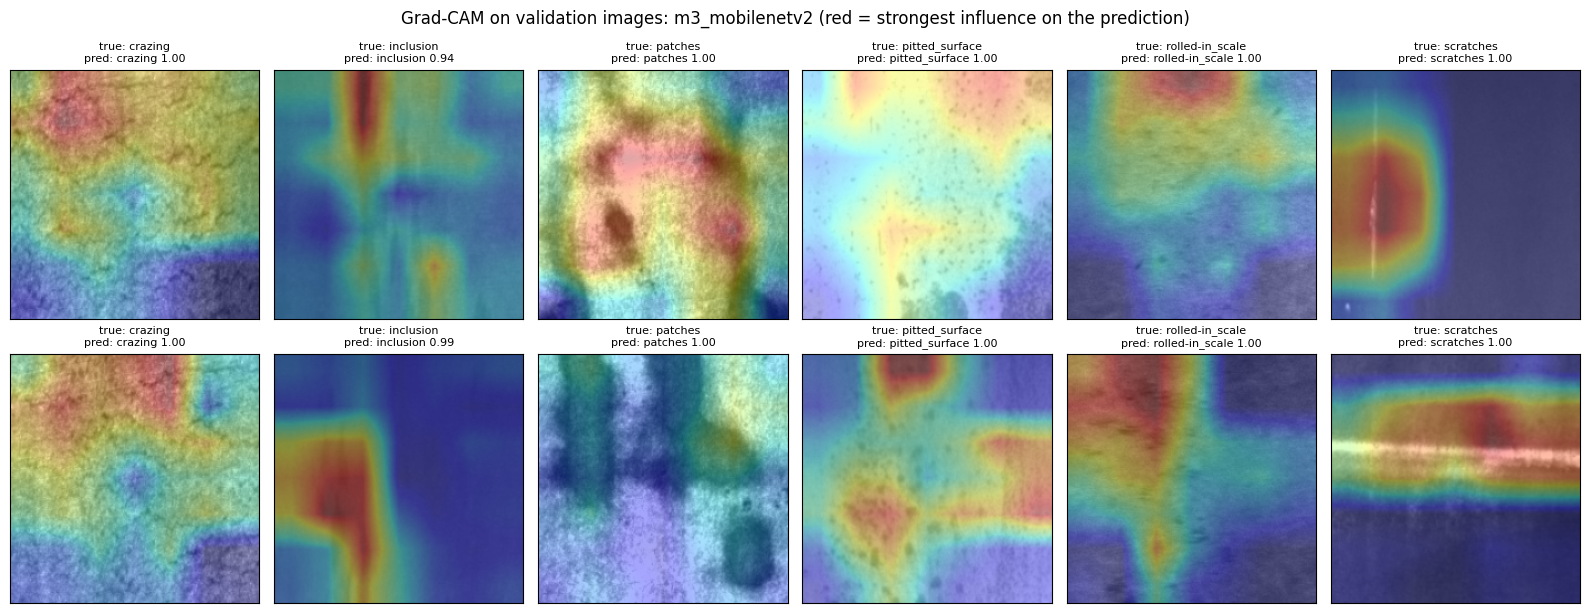

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 200, 200, 1))
  warnings.warn(msg)


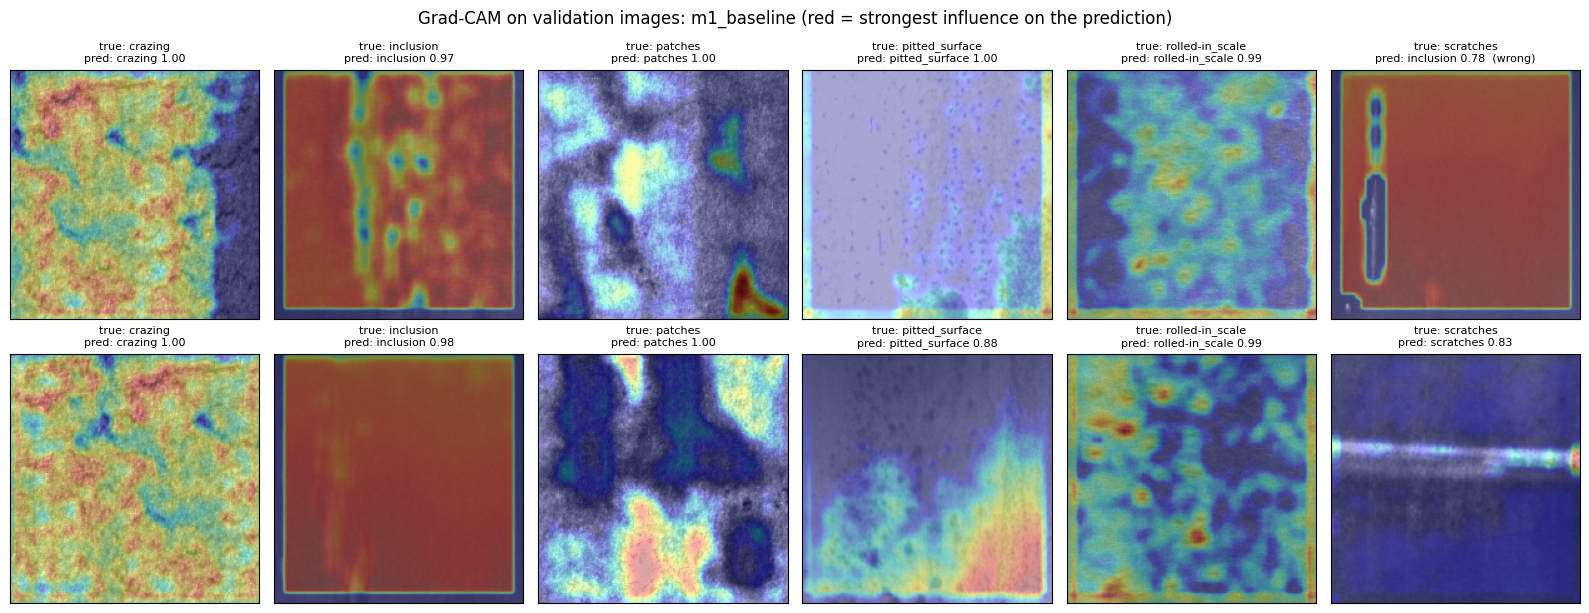

In [3]:
picks = pd.concat([val_df[val_df["label"] == c].head(2) for c in CLASSES]).reset_index(drop=True)
for k, name in enumerate(FINALISTS, start=1):
    gm = grad_model_for(name)
    size = SIZE[name]
    fig, axes = plt.subplots(2, 6, figsize=(16, 6.4))
    for ax, (_, r) in zip(axes.T.ravel(), picks.iterrows()):
        gray = load_gray(r["filepath"], size)
        cam, top, conf = grad_cam(gm, to_model_input(gray, name))
        mark = "" if CLASSES[top] == r["label"] else "  (wrong)"
        overlay(ax, gray, cam, f"true: {r['label']}\npred: {CLASSES[top]} {conf:.2f}{mark}")
    fig.suptitle(f"Grad-CAM on validation images: {name} (red = strongest influence on the prediction)", fontsize=12)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"extra_0{k}_gradcam_{name}.png", dpi=150)
    plt.show()

And the test images that a finalist got wrong (from notebook 06), with the heatmap of the first finalist.

missed test images shown: 12


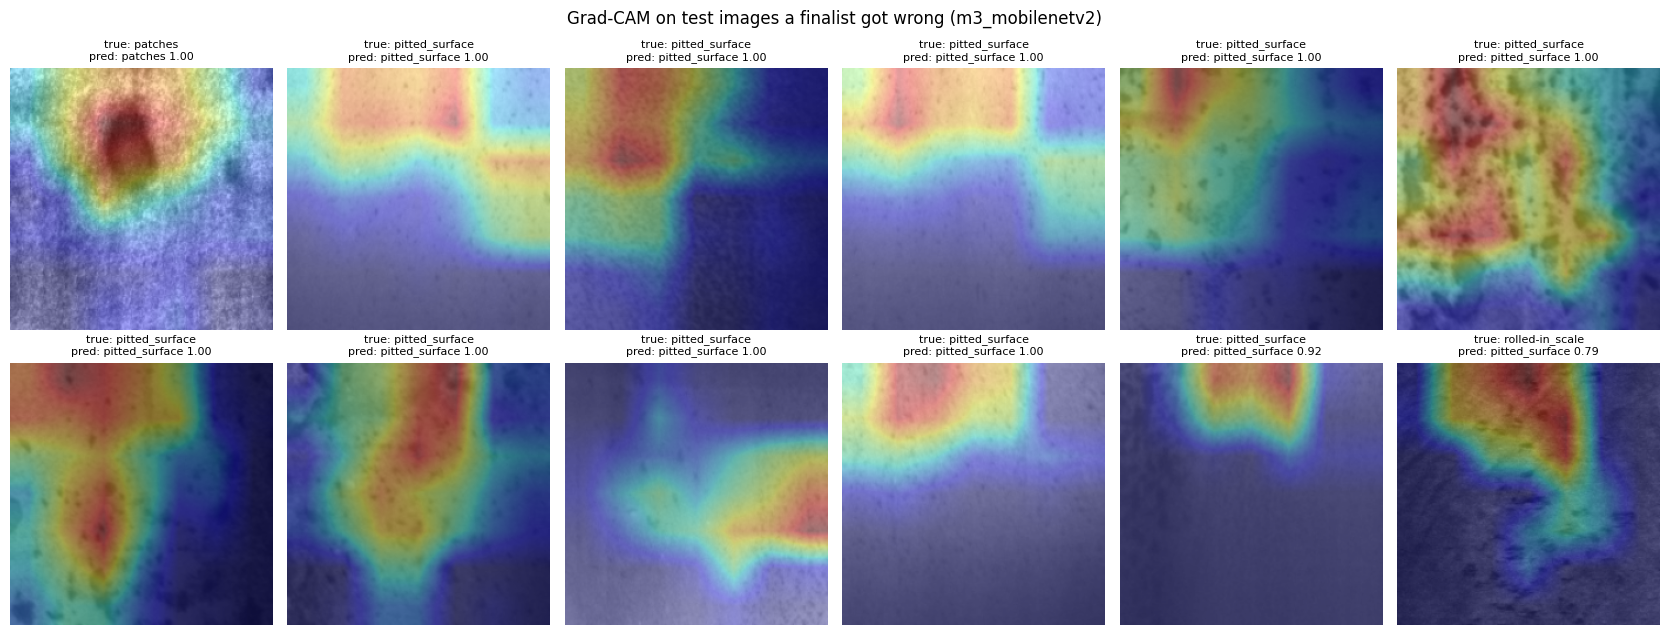

In [4]:
test_pred = pd.read_csv(TEST_PREDICTIONS)
wrong = test_pred[np.any([test_pred[f"pred_{n}"] != test_pred["label"] for n in FINALISTS], axis=0)].head(12)
print("missed test images shown:", len(wrong))
if len(wrong):
    name = FINALISTS[0]
    gm = grad_model_for(name)
    cols = min(len(wrong), 6)
    fig, axes = plt.subplots(int(np.ceil(len(wrong) / cols)), cols, figsize=(2.8 * cols, 3.3 * int(np.ceil(len(wrong) / cols))), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (_, r) in zip(axes.ravel(), wrong.iterrows()):
        gray = load_gray(r["filepath"], SIZE[name])
        cam, top, conf = grad_cam(gm, to_model_input(gray, name))
        overlay(ax, gray, cam, f"true: {r['label']}\npred: {CLASSES[top]} {conf:.2f}")
    fig.suptitle(f"Grad-CAM on test images a finalist got wrong ({name})", fontsize=12)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "extra_03_gradcam_mistakes.png", dpi=150)
    plt.show()

## I2 · Robustness: dirty lens, blur and bad lighting

A steel plant is hot, steamy and dusty, and lights age. We damage the validation images in four ways, each at three strengths, and measure accuracy again. Strength 0 is the clean image. Besides the two finalists we also test M2, the one CNN trained with brightness and contrast augmentation, to see what augmentation buys when the images get worse.

| Damage | Levels | What it imitates |
|---|---|---|
| Gaussian noise | std 0.02, 0.05, 0.10 (pixels on 0..1) | sensor noise, dust |
| Gaussian blur | kernel 3, 5, 9 px | out of focus, steam, vibration |
| Brightness shift | −0.15, −0.30, −0.45 | weaker lights |
| Contrast drop | × 0.8, 0.6, 0.4 around the mean | dirty lens, glare |

In [5]:
rng = np.random.default_rng(SEED)


def gaussian_blur(images, k):
    sigma = 0.3 * ((k - 1) * 0.5 - 1) + 0.8
    ax = np.arange(k) - (k - 1) / 2
    kernel_1d = np.exp(-(ax ** 2) / (2 * sigma ** 2))
    kernel = np.outer(kernel_1d, kernel_1d)
    kernel = (kernel / kernel.sum()).astype(np.float32)[..., None, None]
    return tf.nn.conv2d(images, kernel, strides=1, padding="SAME").numpy()


CORRUPTIONS = {
    "noise": [0.02, 0.05, 0.10],
    "blur": [3, 5, 9],
    "darker": [0.15, 0.30, 0.45],
    "low_contrast": [0.8, 0.6, 0.4],
}


def corrupt(images, kind, level):
    if kind == "noise":
        out = images + rng.normal(0, level, images.shape).astype(np.float32)
    elif kind == "blur":
        out = gaussian_blur(images, level)
    elif kind == "darker":
        out = images - level
    else:
        mean = images.mean(axis=(1, 2, 3), keepdims=True)
        out = mean + (images - mean) * level
    return np.clip(out, 0.0, 1.0).astype(np.float32)


rows = []
for name in ROBUSTNESS_MODELS:
    clean = val_gray[SIZE[name]]
    base_acc = float((models[name].predict(to_model_input(clean, name), verbose=0).argmax(1) == y_val).mean())
    for kind, levels in CORRUPTIONS.items():
        rows.append({"model": name, "corruption": kind, "severity": 0, "level": 0, "accuracy": round(base_acc, 4)})
        for sev, level in enumerate(levels, start=1):
            x = to_model_input(corrupt(clean, kind, level), name)
            acc = float((models[name].predict(x, verbose=0).argmax(1) == y_val).mean())
            rows.append({"model": name, "corruption": kind, "severity": sev, "level": level, "accuracy": round(acc, 4)})

robustness = pd.DataFrame(rows)
robustness.to_csv(RES_DIR / "robustness.csv", index=False)
robustness.pivot_table(index=["corruption", "severity"], columns="model", values="accuracy")

I0000 00:00:1792300921.630639      68 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


model                  m1_baseline  m2_improved  m3_mobilenetv2
corruption   severity                                          
blur         0              0.9704       0.9593          0.9704
             1              0.3852       0.7222          0.9593
             2              0.3259       0.4741          0.9259
             3              0.2556       0.3852          0.8481
darker       0              0.9704       0.9593          0.9704
             1              0.6593       0.8963          0.9667
             2              0.3185       0.5259          0.9667
             3              0.2556       0.4259          0.9185
low_contrast 0              0.9704       0.9593          0.9704
             1              0.8000       0.9778          0.9593
             2              0.3815       0.9407          0.8704
             3              0.2481       0.5259          0.6519
noise        0              0.9704       0.9593          0.9704
             1              0.5815       0.4630          0.9630
             2              0.2926       0.3111          0.8259
             3              0.2444       0.2519          0.4815

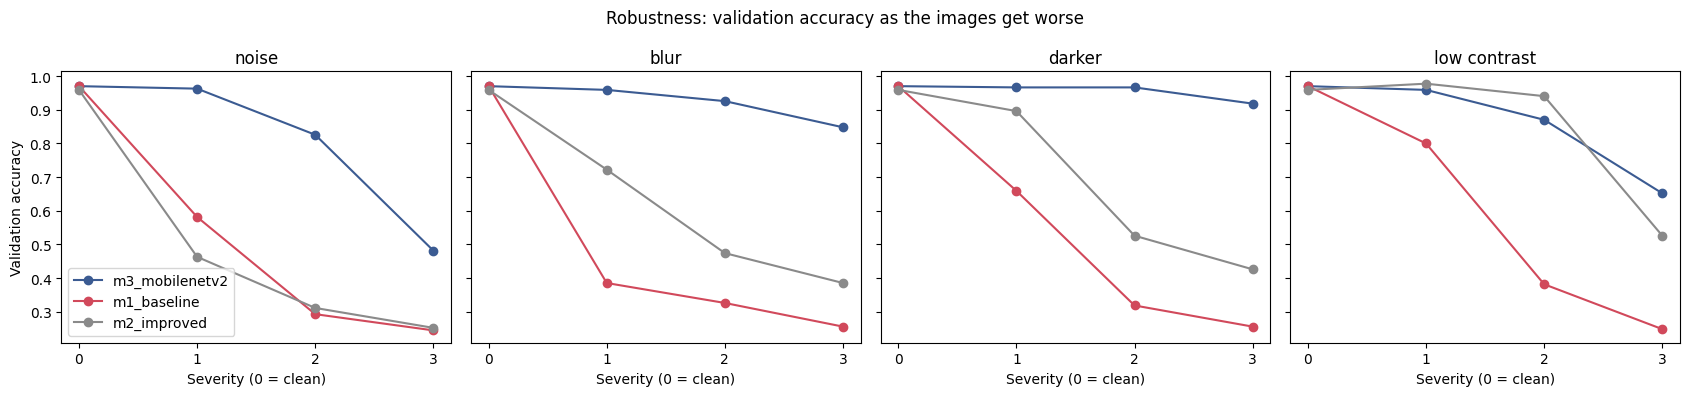

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharey=True)
for ax, kind in zip(axes, CORRUPTIONS):
    for name, color in zip(ROBUSTNESS_MODELS, ("#3b5b92", "#d1495b", "#8a8a8a")):
        part = robustness[(robustness["model"] == name) & (robustness["corruption"] == kind)]
        ax.plot(part["severity"], part["accuracy"], marker="o", label=name, color=color)
    ax.set_title(kind.replace("_", " "))
    ax.set_xlabel("Severity (0 = clean)")
    ax.set_xticks([0, 1, 2, 3])
axes[0].set_ylabel("Validation accuracy")
axes[0].legend()
fig.suptitle("Robustness: validation accuracy as the images get worse", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "extra_04_robustness.png", dpi=150)
plt.show()

## I3 · Augmentation ablation

We retrain the M2 network three times with everything identical except the augmentation, and compare validation accuracy:
- **none:** no augmentation at all;
- **no rotation:** flips, zoom, contrast and brightness, but no rotation;
- **full:** the augmentation used in M2.

Every run uses the same seed, so the difference comes from the augmentation.

In [7]:
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE


def make_dataset(part, shuffle=False):
    paths = [str(DATA_ROOT / p) for p in part["filepath"]]
    labels = [CLASSES.index(c) for c in part["label"]]
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def load(path, label):
        img = tf.io.decode_jpeg(tf.io.read_file(path), channels=1)
        return tf.image.resize(img, (200, 200)) / 255.0, label

    ds = ds.map(load, num_parallel_calls=AUTOTUNE).cache()
    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(AUTOTUNE)


def augmentation(rotation=True):
    layers = [keras.layers.RandomFlip("horizontal_and_vertical", seed=SEED)]
    if rotation:
        layers.append(keras.layers.RandomRotation(0.05, fill_mode="reflect", seed=SEED))
    layers += [
        keras.layers.RandomZoom(0.1, fill_mode="reflect", seed=SEED),
        keras.layers.RandomContrast(0.2, seed=SEED),
        keras.layers.RandomBrightness(0.2, value_range=(0.0, 1.0), seed=SEED),
    ]
    return keras.Sequential(layers, name="augmentation")


def m2_network(augment):
    inputs = keras.Input((200, 200, 1))
    x = augment(inputs) if augment is not None else inputs
    for filters in (32, 64, 128):
        x = keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = keras.layers.BatchNormalization(momentum=0.9)(x)
        x = keras.layers.Activation("relu")(x)
        x = keras.layers.MaxPooling2D(2)(x)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dense(128, activation="relu")(x)
    x = keras.layers.Dropout(0.5)(x)
    outputs = keras.layers.Dense(len(CLASSES), activation="softmax")(x)
    return keras.Model(inputs, outputs)


train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df)
ablation = []
for variant, augment in (("none", None), ("no rotation", augmentation(rotation=False)), ("full", augmentation())):
    keras.utils.set_random_seed(SEED)
    model = m2_network(augment)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-7),
    ]
    start = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=100, callbacks=callbacks, verbose=0)
    best = int(np.argmin(hist.history["val_loss"]))
    ablation.append({
        "augmentation": variant,
        "val_accuracy": round(float(hist.history["val_accuracy"][best]), 4),
        "val_loss": round(float(hist.history["val_loss"][best]), 4),
        "train_accuracy_at_best": round(float(hist.history["accuracy"][best]), 4),
        "epochs": len(hist.history["loss"]),
        "train_time_s": round(time.time() - start, 1),
    })
    print(ablation[-1])

ablation = pd.DataFrame(ablation)
ablation.to_csv(RES_DIR / "ablation.csv", index=False)
ablation

{'augmentation': 'none', 'val_accuracy': 1.0, 'val_loss': 0.0147, 'train_accuracy_at_best': 0.9857, 'epochs': 91, 'train_time_s': 190.7}
{'augmentation': 'no rotation', 'val_accuracy': 0.9926, 'val_loss': 0.0558, 'train_accuracy_at_best': 0.9603, 'epochs': 45, 'train_time_s': 169.3}
{'augmentation': 'full', 'val_accuracy': 0.9556, 'val_loss': 0.1677, 'train_accuracy_at_best': 0.954, 'epochs': 38, 'train_time_s': 140.9}


,augmentation,val_accuracy,val_loss,train_accuracy_at_best,epochs,train_time_s
0,none,1.0000,0.0147,0.9857,91,190.7
1,no rotation,0.9926,0.0558,0.9603,45,169.3
2,full,0.9556,0.1677,0.9540,38,140.9


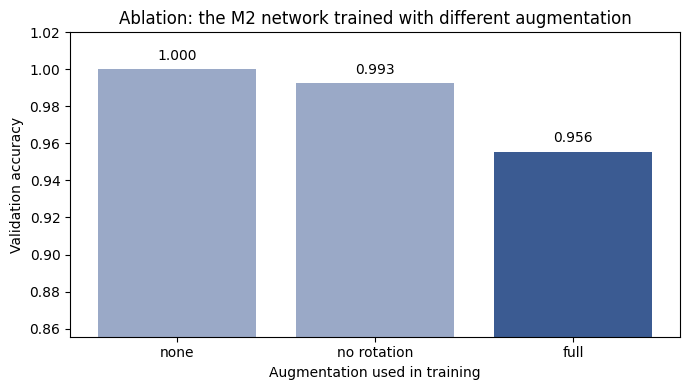

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(ablation["augmentation"], ablation["val_accuracy"], color=["#9aa9c7", "#9aa9c7", "#3b5b92"])
for i, v in enumerate(ablation["val_accuracy"]):
    ax.text(i, v + 0.005, f"{v:.3f}", ha="center")
ax.set_ylim(max(0.0, ablation["val_accuracy"].min() - 0.1), 1.02)
ax.set_xlabel("Augmentation used in training")
ax.set_ylabel("Validation accuracy")
ax.set_title("Ablation: the M2 network trained with different augmentation")
fig.tight_layout()
fig.savefig(FIG_DIR / "extra_05_ablation.png", dpi=150)
plt.show()

## I4 · TensorFlow Lite for a small device

TensorFlow Lite turns a Keras model into a compact file for phones and small boards. We convert an inference copy of each model: the same layers and weights without the augmentation block, which does nothing at prediction time and whose random operations TensorFlow Lite cannot convert.

With dynamic-range quantisation the weights are stored as 8-bit integers instead of 32-bit floats, which makes the file about four times smaller. We check that it still gives the same answers on the validation set and time it on the CPU, one image at a time.

In [9]:
def inference_copy(model):
    inp = keras.Input(model.input_shape[1:])
    x = inp
    for layer in model.layers:
        if isinstance(layer, keras.layers.InputLayer) or layer.name == "augmentation":
            continue
        x = layer(x)
    return keras.Model(inp, x)


tflite_rows = []
for name in FINALISTS:
    export_dir = MODEL_DIR / f"{name}_savedmodel"
    inference_copy(models[name]).export(str(export_dir), verbose=False)
    converter = tf.lite.TFLiteConverter.from_saved_model(str(export_dir))
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    tflite_bytes = converter.convert()
    path = MODEL_DIR / f"{name}.tflite"
    path.write_bytes(tflite_bytes)

    interpreter = tf.lite.Interpreter(model_content=tflite_bytes)
    interpreter.allocate_tensors()
    inp, out = interpreter.get_input_details()[0], interpreter.get_output_details()[0]
    x_all = to_model_input(val_gray[SIZE[name]], name).astype(np.float32)
    preds, times = [], []
    for i in range(len(x_all)):
        interpreter.set_tensor(inp["index"], x_all[i:i + 1])
        start = time.perf_counter()
        interpreter.invoke()
        times.append(time.perf_counter() - start)
        preds.append(int(interpreter.get_tensor(out["index"]).argmax()))
    keras_preds = models[name].predict(x_all, verbose=0).argmax(1)
    tflite_rows.append({
        "model": name,
        "keras_size_mb": round(MODEL_FILES[name].stat().st_size / 1e6, 2),
        "tflite_size_mb": round(len(tflite_bytes) / 1e6, 2),
        "keras_val_accuracy": round(float((keras_preds == y_val).mean()), 4),
        "tflite_val_accuracy": round(float((np.array(preds) == y_val).mean()), 4),
        "same_prediction_share": round(float((np.array(preds) == keras_preds).mean()), 4),
        "tflite_cpu_ms_per_image": round(float(np.median(times)) * 1000, 2),
    })

tflite = pd.DataFrame(tflite_rows)
tflite.to_csv(RES_DIR / "tflite.csv", index=False)
tflite

INFO:tensorflow:Assets written to: /kaggle/working/outputs/models/m3_mobilenetv2_savedmodel/assets


INFO:tensorflow:Assets written to: /kaggle/working/outputs/models/m3_mobilenetv2_savedmodel/assets
W0000 00:00:1792301446.516865      20 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792301446.516898      20 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1792301446.634624      20 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


INFO:tensorflow:Assets written to: /kaggle/working/outputs/models/m1_baseline_savedmodel/assets


INFO:tensorflow:Assets written to: /kaggle/working/outputs/models/m1_baseline_savedmodel/assets
W0000 00:00:1792301456.555090      20 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792301456.555122      20 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


,model,keras_size_mb,tflite_size_mb,keras_val_accuracy,tflite_val_accuracy,same_prediction_share,tflite_cpu_ms_per_image
0,m3_mobilenetv2,24.46,2.51,0.9704,0.9741,0.9963,18.03
1,m1_baseline,1.38,0.12,0.9704,0.9704,1.0000,10.14


## Save the summary

In [10]:
summary = {
    "finalists": FINALISTS,
    "robustness": robustness.to_dict(orient="records"),
    "ablation": ablation.to_dict(orient="records"),
    "tflite": tflite.to_dict(orient="records"),
}
(RES_DIR / "extras_summary.json").write_text(json.dumps(summary, indent=2))
print("saved")

saved


## What we found

- **Grad-CAM, MobileNetV2 looks at the defect:** the scratch line, the inclusion streak and the dark patches light up. **M1 often looks at the background instead:** for inclusion it lights up the flat steel around the defect, and on the scratch it got wrong the background is red and the scratch itself is not. EDA showed inclusion images are the flattest, so M1 learned "flat background means inclusion", a shortcut.
- **Robustness:** MobileNetV2 holds up best: 92.6 % with a 5 px blur and 91.9 % with the lights 0.45 darker. M1 collapses quickly (65.9 % at the first darkening step, 38.5 % with a 3 px blur, 58.2 % with slight noise), which fits the shortcut above. M2, trained with brightness and contrast augmentation, is far more robust to lighting than M1 (89.6 % vs 65.9 % one step darker, 94.1 % vs 38.2 % at 0.6 contrast) but not to noise. Strong noise (std 0.10) hurts every model; MobileNetV2 drops to 48.1 %.
- **Ablation:** the M2 network scored 100 % on validation without augmentation, 99.26 % without rotation and 95.56 % with the full set. An earlier run of this notebook gave the same order (100 %, 98.89 %, 94.07 %). On clean NEU images augmentation costs accuracy, and rotation costs the most, because scratches and rolled-in scale follow the rolling direction. The flip side is the robustness result above: augmentation is what keeps a model working when the lighting changes.
- **TensorFlow Lite:** MobileNetV2 shrinks from 24.46 MB to 2.51 MB and gives the same answer as the full model on 99.63 % of validation images (97.41 % accuracy). It runs in 18.0 ms per image on Kaggle's CPU, against 224 ms for the Keras model in notebook 06. M1 shrinks to 0.12 MB at 10.1 ms per image.